# Desafio do Oráculo Preditivo
## Ecommerce Customers

### Grupo 01

- Apolo Bastos
- Nicolas Gabriel
- Caio Simonassi
- Gabriel Nito
- Jônatas

## 1. Introdução e Contextualização

Este projeto utiliza o dataset Ecommerce Customers para estudar um problema de regressão relacionado ao comportamento de clientes de um e-commerce. Nesta etapa, além de conhecer a estrutura dos dados, foi estabelecido o protocolo mínimo de preparação para os modelos futuros e foi concluída a Análise Exploratória de Dados sobre o conjunto de treinamento.

## 2. Objetivo do Projeto

O objetivo final do trabalho será comparar diferentes abordagens de regressão para prever uma variável contínua. Nesta etapa, a variável-alvo e o conjunto de preditoras são definidos, os dados são separados em treino e teste e o escalonamento é preparado sem treinar regressores. A análise exploratória detalhada também será documentada neste notebook, sempre separada da modelagem futura.

## 3. Importação das Bibliotecas

Serão utilizadas bibliotecas simples para carregar, explorar e preparar os dados. O pandas organiza o DataFrame, o NumPy apoia o diagnóstico numérico, o Matplotlib produz gráficos e o scikit-learn fornece a divisão aleatória reproduzível e o StandardScaler.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 4. Carregamento do Dataset

O arquivo foi mantido com o nome real disponibilizado pelo dataset. Como esta célula deve ser executada a partir da pasta `notebooks/`, o caminho relativo aponta para `../data/Ecommerce Customers`.

In [2]:
arquivo_dataset = "../data/Ecommerce Customers"
df = pd.read_csv(arquivo_dataset)

print("DataFrame criado com sucesso.")
print(f"Arquivo carregado: {arquivo_dataset}")

DataFrame criado com sucesso.
Arquivo carregado: ../data/Ecommerce Customers


## 5. Inspeção Inicial dos Dados

A inspeção inicial ajuda a verificar o conteúdo, o tamanho, a estrutura e a qualidade básica do dataset antes de qualquer decisão de pré-processamento ou modelagem.

### 5.1 Primeiras linhas

A visualização das primeiras linhas permite conferir exemplos dos registros e observar como as colunas estão organizadas no DataFrame.

In [3]:
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


### 5.2 Dimensões do dataset

A propriedade `shape` informa a quantidade de linhas e colunas presentes no DataFrame.

In [4]:
quantidade_linhas, quantidade_colunas = df.shape
print(f"Quantidade de linhas: {quantidade_linhas}")
print(f"Quantidade de colunas: {quantidade_colunas}")

Quantidade de linhas: 500
Quantidade de colunas: 8


### 5.3 Estrutura e tipos de dados

O método `info()` apresenta um resumo da estrutura do DataFrame, incluindo a quantidade de entradas, as colunas, os tipos de dados e a presença de valores não nulos.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.3 KB


Os tipos das colunas também podem ser observados em uma tabela para facilitar a leitura.

In [6]:
df.dtypes.to_frame(name="Tipo de dado")

,Tipo de dado
Email,str
Address,str
Avatar,str
Avg. Session Length,float64
Time on App,float64
Time on Website,float64
Length of Membership,float64
Yearly Amount Spent,float64


### 5.4 Identificação das variáveis

A tabela a seguir reúne o nome de cada coluna, o tipo identificado pelo pandas e uma classificação preliminar como numérica ou categórica/textual. Essa classificação descreve o que está presente no arquivo; a decisão de uso no modelo será justificada na Etapa 02.

In [7]:
classificacoes = [
    "numérica" if pd.api.types.is_numeric_dtype(tipo) else "categórica/textual"
    for tipo in df.dtypes
]

tabela_variaveis = pd.DataFrame({
    "Nome da coluna": df.columns,
    "Tipo de dado": df.dtypes.astype(str).values,
    "Classificação preliminar": classificacoes,
})

tabela_variaveis

,Nome da coluna,Tipo de dado,Classificação preliminar
0,Email,str,categórica/textual
1,Address,str,categórica/textual
2,Avatar,str,categórica/textual
3,Avg. Session Length,float64,numérica
4,Time on App,float64,numérica
5,Time on Website,float64,numérica
6,Length of Membership,float64,numérica
7,Yearly Amount Spent,float64,numérica


### 5.5 Valores ausentes

A soma de valores nulos por coluna oferece uma verificação inicial de dados ausentes. Nenhum tratamento será realizado agora.

In [8]:
valores_ausentes = df.isnull().sum()
valores_ausentes.to_frame(name="Quantidade de valores ausentes")

,Quantidade de valores ausentes
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


Na inspeção realizada, não foram identificados valores nulos no dataset. O tratamento de valores ausentes permanece fora do escopo desta etapa.

### 5.6 Registros duplicados

A verificação abaixo conta as linhas completamente duplicadas. Nenhum registro será removido nesta etapa.

In [9]:
quantidade_duplicatas = df.duplicated().sum()
print(f"Quantidade de registros duplicados: {quantidade_duplicatas}")

Quantidade de registros duplicados: 0


A inspeção inicial não encontrou linhas completamente duplicadas no dataset. A análise de duplicatas está encerrada sem alterar os dados.

## 6. Observações Iniciais

Com base apenas na inspeção inicial, o dataset contém 500 registros e 8 variáveis. Não foram identificados valores ausentes nem linhas completamente duplicadas. Há cinco variáveis numéricas e três variáveis categóricas/textuais. A definição do target e a preparação para treino/teste são documentadas a seguir; a EDA detalhada utiliza somente o conjunto de treinamento e não inclui modelagem ou métricas preditivas.

## 7. Definição da variável-alvo e do problema de regressão

Queremos prever o valor gasto anualmente por um cliente a partir de informações relacionadas ao seu uso do e-commerce e ao seu relacionamento com a empresa. Como o resultado esperado é um número contínuo, o problema é de regressão.

A separação conceitual será:

- **Target (`y`)**: valor que queremos prever.
- **Features (`X`)**: informações utilizadas para realizar a previsão.

A coluna `Yearly Amount Spent` é a candidata natural para o target porque representa o valor gasto anualmente pelo cliente. A decisão será confirmada no arquivo real antes de separar `X` e `y`. As demais colunas serão analisadas como possíveis preditoras ou como informações a excluir.

In [10]:
variavel_alvo = 'Yearly Amount Spent'

if variavel_alvo not in df.columns:
    raise KeyError(f'A coluna-alvo não foi encontrada: {variavel_alvo}')

if not pd.api.types.is_numeric_dtype(df[variavel_alvo]):
    raise TypeError('A variável-alvo precisa ser numérica para este problema de regressão.')

print(f'Variável-alvo confirmada: {variavel_alvo}')
print(f'Tipo da variável-alvo: {df[variavel_alvo].dtype}')
print('Interpretação: valor gasto anualmente por cliente.')

Variável-alvo confirmada: Yearly Amount Spent
Tipo da variável-alvo: float64
Interpretação: valor gasto anualmente por cliente.


A coluna foi encontrada no CSV e possui tipo numérico. Portanto, `Yearly Amount Spent` será a variável dependente (`y`) e não poderá aparecer entre as features. As colunas de uso e de relacionamento com a empresa são candidatas a variáveis independentes, mas a decisão final também considera natureza, utilidade plausível, ruído e risco de identificação.

## 8. Seleção e justificativa das variáveis

A seleção não será feita apenas pela conveniência de manter todas as colunas numéricas. Cada coluna é classificada explicitamente como target, feature ou excluída da modelagem. Primeiro observamos a cardinalidade dos campos textuais; depois registramos a decisão para todas as colunas reais do dataset.

In [11]:
colunas_textuais = df.select_dtypes(exclude='number').columns.tolist()
print('Cardinalidade dos campos textuais:')
print(df[colunas_textuais].nunique().to_frame(name='Valores distintos'))

colunas_features = [
    'Avg. Session Length',
    'Time on App',
    'Time on Website',
    'Length of Membership',
]
colunas_excluidas = ['Email', 'Address', 'Avatar']

decisoes = {
    'Email': {
        'Papel': 'excluída da modelagem',
        'Decisão': 'excluir',
        'Justificativa': 'identificador textual de alta cardinalidade; não descreve diretamente o comportamento de uso',
    },
    'Address': {
        'Papel': 'excluída da modelagem',
        'Decisão': 'excluir',
        'Justificativa': 'texto identificador de alta cardinalidade; transformar o endereço em categorias introduziria ruído e memorização',
    },
    'Avatar': {
        'Papel': 'excluída da modelagem',
        'Decisão': 'excluir',
        'Justificativa': 'rótulo textual sem significado preditivo justificado para o gasto anual neste experimento',
    },
    'Avg. Session Length': {
        'Papel': 'feature',
        'Decisão': 'utilizar',
        'Justificativa': 'mede a duração média da sessão e representa comportamento de uso do e-commerce',
    },
    'Time on App': {
        'Papel': 'feature',
        'Decisão': 'utilizar',
        'Justificativa': 'mede o tempo de uso do aplicativo e é plausivelmente relacionado ao consumo',
    },
    'Time on Website': {
        'Papel': 'feature',
        'Decisão': 'utilizar',
        'Justificativa': 'mede o tempo de uso do website e é plausivelmente relacionado ao consumo',
    },
    'Length of Membership': {
        'Papel': 'feature',
        'Decisão': 'utilizar',
        'Justificativa': 'mede a duração do relacionamento do cliente com a empresa',
    },
    'Yearly Amount Spent': {
        'Papel': 'target',
        'Decisão': 'prever',
        'Justificativa': 'representa o valor gasto anualmente pelo cliente e é a variável dependente',
    },
}

if set(decisoes) != set(df.columns):
    raise ValueError('A tabela de decisões não cobre exatamente as colunas do dataset.')

if set(colunas_features + [variavel_alvo] + colunas_excluidas) != set(df.columns):
    raise ValueError('Features, target e exclusões não cobrem exatamente as colunas do dataset.')

tabela_decisoes = pd.DataFrame.from_dict(decisoes, orient='index')
tabela_decisoes.index.name = 'Coluna'
tabela_decisoes.reset_index()

Cardinalidade dos campos textuais:
         Valores distintos
Email                  500
Address                500
Avatar                 138


,Coluna,Papel,Decisão,Justificativa
0,Email,excluída da modelagem,excluir,identificador textual de alta cardinalidade; n...
1,Address,excluída da modelagem,excluir,texto identificador de alta cardinalidade; tra...
2,Avatar,excluída da modelagem,excluir,rótulo textual sem significado preditivo justi...
3,Avg. Session Length,feature,utilizar,mede a duração média da sessão e representa co...
4,Time on App,feature,utilizar,mede o tempo de uso do aplicativo e é plausive...
5,Time on Website,feature,utilizar,mede o tempo de uso do website e é plausivelme...
6,Length of Membership,feature,utilizar,mede a duração do relacionamento do cliente co...
7,Yearly Amount Spent,target,prever,representa o valor gasto anualmente pelo clien...


Os quatro atributos numéricos de uso e relacionamento serão utilizados como features. `Email`, `Address` e `Avatar` serão excluídos porque são textos identificadores ou sem significado preditivo justificado para este objetivo. A exclusão é explícita e não altera o DataFrame original.

### 8.1 Tratamento de variáveis categóricas

As três colunas textuais foram analisadas, mas nenhuma será utilizada como preditora. Por isso, não será aplicado One-Hot Encoding nem Label Encoding. Essa escolha evita transformar identificadores de alta cardinalidade em muitas colunas ou atribuir números ordinais artificiais a categorias nominais.

Se uma variável categórica fosse necessária em uma etapa futura, a transformação teria de ser ajustada apenas no conjunto de treinamento e aplicada ao teste sem aprender novos parâmetros. Para o protocolo atual, a alternativa metodologicamente adequada é não incluir essas colunas.

In [12]:
colunas_categoricas_utilizadas = [
    coluna for coluna in colunas_features
    if not pd.api.types.is_numeric_dtype(df[coluna])
]

assert colunas_categoricas_utilizadas == []
print('Variáveis categóricas utilizadas no modelo futuro: nenhuma')
print('Encoding categórico: não aplicado, pois todas as colunas textuais foram excluídas com justificativa.')

Variáveis categóricas utilizadas no modelo futuro: nenhuma
Encoding categórico: não aplicado, pois todas as colunas textuais foram excluídas com justificativa.


## 9. Separação entre X e y

Agora preparamos as variáveis independentes e a variável-alvo usando os nomes convencionais `X` e `y`. São criadas cópias apenas das colunas selecionadas, preservando o DataFrame original para consultas posteriores.

In [13]:
X = df[colunas_features].copy()
y = df[variavel_alvo].copy()

assert len(X) == len(y)
assert variavel_alvo not in X.columns

print(f'Features selecionadas: {X.columns.tolist()}')
print(f'Dimensões de X: {X.shape}')
print(f'Dimensões de y: {y.shape}')
print(f'Tipo da variável-alvo: {y.dtype}')
print(f'Target presente em X: {variavel_alvo in X.columns}')

Features selecionadas: ['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']
Dimensões de X: (500, 4)
Dimensões de y: (500,)
Tipo da variável-alvo: float64
Target presente em X: False


A verificação confirma que `X` contém somente as quatro features escolhidas e que `y` contém a coluna `Yearly Amount Spent`. Ambos têm a mesma quantidade de registros, mas o target não aparece entre as features.

## 10. Divisão entre treino e teste

Será utilizada uma única divisão para os três algoritmos futuros: 80% dos registros para treinamento e 20% para teste. O `random_state=42` torna o sorteio reproduzível, permitindo que os modelos sejam comparados sobre exatamente os mesmos registros. O conjunto de teste ficará isolado das decisões de ajuste e seleção.

In [14]:
test_size = 0.20
random_state = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_size,
    random_state=random_state,
)

print(f'Proporção de teste: {test_size:.0%}')
print(f'random_state: {random_state}')
print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}')
print(f'y_test: {y_test.shape}')

Proporção de teste: 20%
random_state: 42
X_train: (400, 4)
X_test: (100, 4)
y_train: (400,)
y_test: (100,)


Treino é o conjunto utilizado futuramente para aprender padrões. Teste é o conjunto reservado para avaliar a capacidade de generalização depois que as decisões de ajuste forem tomadas. Como o dataset possui 500 registros, a execução deve produzir 400 observações de treino e 100 de teste. Nenhuma divisão independente será criada para cada algoritmo.

### 10.1 Verificações da divisão

As verificações abaixo conferem dimensões, colunas, soma dos registros, separação dos índices e reprodutibilidade da mesma seed. Elas não afirmam independência estatística nem qualidade preditiva.

In [15]:
assert len(X) == len(y)
assert variavel_alvo not in X.columns
assert X_train.columns.equals(X_test.columns)
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

X_train_reprod, X_test_reprod, y_train_reprod, y_test_reprod = train_test_split(
    X, y, test_size=test_size, random_state=random_state
)

assert X_train.index.equals(X_train_reprod.index)
assert X_test.index.equals(X_test_reprod.index)
assert y_train.index.equals(y_train_reprod.index)
assert y_test.index.equals(y_test_reprod.index)

print('1. X e y possuem a mesma quantidade de registros: OK')
print('2. O target não está presente em X: OK')
print('3. Treino e teste possuem as mesmas colunas: OK')
print('4. A soma de treino e teste corresponde ao dataset: OK')
print('5. Os índices de treino e teste são disjuntos: OK')
print('6. A divisão é reproduzível com a mesma seed: OK')

1. X e y possuem a mesma quantidade de registros: OK
2. O target não está presente em X: OK
3. Treino e teste possuem as mesmas colunas: OK
4. A soma de treino e teste corresponde ao dataset: OK
5. Os índices de treino e teste são disjuntos: OK
6. A divisão é reproduzível com a mesma seed: OK


## 11. Estratégia de escalonamento

A padronização transforma cada feature para uma escala baseada na média e no desvio-padrão aprendidos nos dados de treinamento. Isso é especialmente importante para o SVR, pois a distância entre observações e a margem do modelo são sensíveis à escala das variáveis.

Random Forest geralmente não precisa de padronização para comparar divisões em árvores. Na Regressão Linear sem regularização, a capacidade de representar uma combinação linear equivalente não depende da escala em condições usuais, embora a padronização possa ajudar na estabilidade numérica e na comparação dos coeficientes.

A regra contra vazamento é obrigatória: `fit_transform()` aprende parâmetros somente em `X_train`; `transform()` reaproveita esses parâmetros em `X_test`. O target permanece em sua escala original para conservar a unidade de gasto anual.

In [16]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

resumo_escalonamento = pd.DataFrame({
    'Média no treino escalonado': X_train_scaled.mean(),
    'Desvio-padrão no treino escalonado': X_train_scaled.std(ddof=0),
})

print('fit_transform() aplicado somente em X_train.')
print('transform() aplicado em X_test usando os parâmetros do treino.')
print(f'Amostras usadas para aprender o scaler: {int(scaler.n_samples_seen_)}')
resumo_escalonamento.round(3)

fit_transform() aplicado somente em X_train.
transform() aplicado em X_test usando os parâmetros do treino.
Amostras usadas para aprender o scaler: 400


,Média no treino escalonado,Desvio-padrão no treino escalonado
Avg. Session Length,-0.0,1.0
Time on App,0.0,1.0
Time on Website,-0.0,1.0
Length of Membership,-0.0,1.0


As versões `X_train_scaled` e `X_test_scaled` mantêm os nomes e os índices das features originais. O conjunto de teste foi apenas transformado; ele não participou do cálculo da média ou do desvio-padrão. Assim, o teste continua representando dados não vistos pelo procedimento de ajuste.

## 12. Preparação para validação cruzada

Na próxima etapa, a validação cruzada dividirá o conjunto de treinamento em diferentes folds. O `StandardScaler` deverá ficar dentro de um `Pipeline` do scikit-learn junto com cada regressor, para que cada fold aprenda média e desvio-padrão apenas da sua própria parte de treinamento.

A estrutura conceitual será semelhante a:

```python
Pipeline([('scaler', StandardScaler()), ('regressor', regressor)])
```

Esse exemplo é apenas uma orientação metodológica nesta etapa. Não serão treinados regressores nem implementados `GridSearchCV` ou `RandomizedSearchCV` agora.

In [17]:
media_aprendida = pd.Series(scaler.mean_, index=X_train.columns)

assert (media_aprendida - X_train.mean()).abs().max() < 1e-12
assert int(scaler.n_samples_seen_) == len(X_train)
assert X_train_scaled.columns.equals(X_train.columns)
assert X_test_scaled.columns.equals(X_test.columns)
assert X_train_scaled.index.equals(X_train.index)
assert X_test_scaled.index.equals(X_test.index)

print('7. Os parâmetros do scaler foram aprendidos somente com X_train: OK')
print('X_train_scaled e X_test_scaled preservam as colunas e os índices originais: OK')

7. Os parâmetros do scaler foram aprendidos somente com X_train: OK
X_train_scaled e X_test_scaled preservam as colunas e os índices originais: OK


## 13. Conclusão da Etapa 02

O target escolhido é `Yearly Amount Spent`, pois representa o valor gasto anualmente pelo cliente e é uma variável numérica contínua. As features utilizadas serão `Avg. Session Length`, `Time on App`, `Time on Website` e `Length of Membership`, todas relacionadas ao uso do serviço ou à duração do relacionamento.

`Email`, `Address` e `Avatar` foram excluídas por serem identificadores ou textos sem significado preditivo justificado para este experimento. Como nenhuma variável categórica foi mantida, não foi necessário aplicar encoding.

A divisão única utiliza 80% para treino e 20% para teste, com `random_state=42` para permitir a reprodução e a comparação justa dos três algoritmos futuros. O `StandardScaler` é ajustado apenas com `X_train` e depois aplicado a `X_test`; durante a validação cruzada, esse ajuste deverá ocorrer dentro de um `Pipeline` em cada fold.

Com isso, os dados estão organizados para a futura implementação da Regressão Linear Múltipla, do Random Forest Regressor e do SVR. Nenhum modelo foi treinado nesta etapa. A análise exploratória detalhada será realizada na seção seguinte, sem alterar o protocolo de treino, teste ou escalonamento.

## 14. Análise Exploratória dos Dados (EDA)

A análise exploratória a seguir utiliza exclusivamente `X_train` e `y_train`, que contêm 400 registros. Essa escolha evita que informações do conjunto de teste influenciem decisões metodológicas antes da avaliação futura dos modelos.

Os gráficos e tabelas são calculados nas unidades originais do dataset. A variável `Yearly Amount Spent` não será interpretada como uma moeda específica.

In [18]:
dados_eda = X_train.copy()
dados_eda[variavel_alvo] = y_train.reindex(dados_eda.index)
dados_eda = dados_eda[[*colunas_features, variavel_alvo]]

assert dados_eda.index.equals(X_train.index)
assert len(dados_eda) == len(X_train) == 400
assert not dados_eda.index.isin(X_test.index).any()

diretorio_figuras = Path('../presentation/slides/ecommerce-oracle/assets')
diretorio_figuras.mkdir(parents=True, exist_ok=True)

print(f'Dados utilizados na EDA: {dados_eda.shape[0]} registros de treinamento.')
print('O alinhamento de X_train e y_train foi preservado pelos índices.')
dados_eda.head()

Dados utilizados na EDA: 400 registros de treinamento.
O alinhamento de X_train e y_train foi preservado pelos índices.


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
249,33.780157,11.917636,36.844734,3.634996,518.786483
433,34.278248,11.822722,36.308545,2.117383,434.144202
19,32.617856,13.989593,37.190504,4.064549,605.061039
322,33.264632,10.732131,36.145792,4.086566,478.262126
332,33.144234,11.737041,37.935189,2.190132,424.202827


### 14.1 Estatística descritiva

A tabela resume contagem, média, mediana, desvio-padrão, quartis e extremos das quatro features e do target. A média e a mediana ajudam a comparar a posição central, mas sua proximidade isolada não comprova normalidade. As diferenças de escala também não representam, por si só, diferenças de importância preditiva.

In [19]:
estatisticas_base = dados_eda.describe().T

estatisticas_descritivas = pd.DataFrame({
    'Contagem': estatisticas_base['count'],
    'Média': estatisticas_base['mean'],
    'Mediana': dados_eda.median(),
    'Desvio-padrão': estatisticas_base['std'],
    'Mínimo': estatisticas_base['min'],
    'Q1': dados_eda.quantile(0.25),
    'Q3': dados_eda.quantile(0.75),
    'Máximo': estatisticas_base['max'],
})

estatisticas_descritivas.round(3)

,Contagem,Média,Mediana,Desvio-padrão,Mínimo,Q1,Q3,Máximo
Avg. Session Length,400.0,33.061,33.103,0.988,29.532,32.335,33.737,35.860
Time on App,400.0,12.058,12.012,0.999,8.508,11.394,12.760,15.127
Time on Website,400.0,37.021,37.042,1.018,33.914,36.312,37.684,39.673
Length of Membership,400.0,3.568,3.590,1.028,0.270,2.956,4.142,6.923
Yearly Amount Spent,400.0,501.992,502.010,81.182,256.671,445.578,554.183,765.518


No treino, `Yearly Amount Spent` apresenta média de aproximadamente 501,992 e mediana de 502,010, com desvio-padrão de 81,182 e intervalo entre 256,671 e 765,518. As quatro features também têm dispersões moderadas em suas próprias unidades. A proximidade entre média e mediana descreve a posição central observada, mas não autoriza concluir que as distribuições sejam normais.

### 14.2 Distribuição da variável-alvo

O histograma mostra a distribuição de `Yearly Amount Spent` nos 400 registros de treino. A assimetria é calculada explicitamente para complementar a leitura visual, sem assumir uma distribuição teórica.

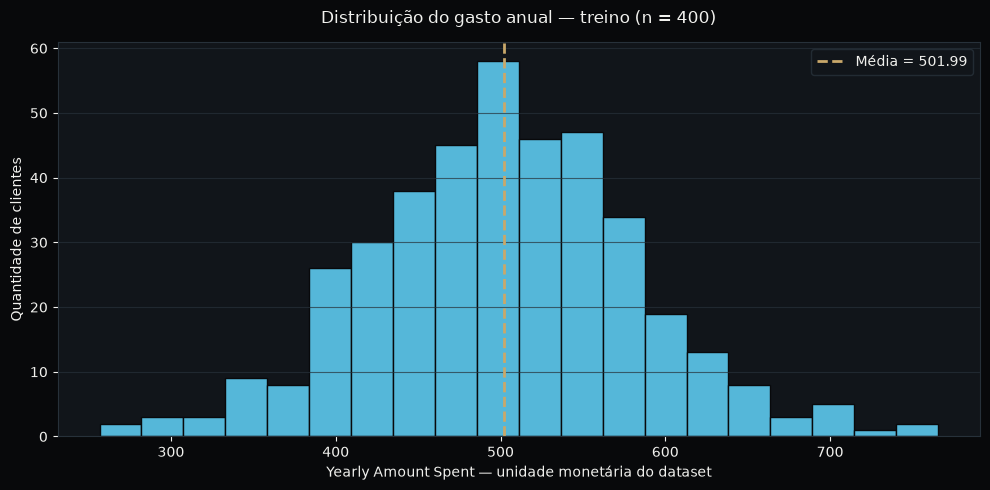

Assimetria de Yearly Amount Spent no treino: 0.068


In [20]:
assimetria_target = dados_eda[variavel_alvo].skew()
media_target = dados_eda[variavel_alvo].mean()

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#08090B')
ax.set_facecolor('#11151A')
ax.hist(dados_eda[variavel_alvo], bins=20, color='#55B7D9', edgecolor='#08090B')
ax.axvline(media_target, color='#C9A86A', linestyle='--', linewidth=2, label=f'Média = {media_target:.2f}')
ax.set_title('Distribuição do gasto anual — treino (n = 400)', color='#F1F1EE', pad=14)
ax.set_xlabel('Yearly Amount Spent — unidade monetária do dataset', color='#F1F1EE')
ax.set_ylabel('Quantidade de clientes', color='#F1F1EE')
ax.tick_params(colors='#F1F1EE')
ax.grid(axis='y', color='#27313A', alpha=0.7)
ax.legend(facecolor='#11151A', edgecolor='#27313A', labelcolor='#F1F1EE')
for spine in ax.spines.values():
    spine.set_color('#27313A')
fig.tight_layout()
fig.savefig(diretorio_figuras / 'eda-target-distribution.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()
print(f'Assimetria de Yearly Amount Spent no treino: {assimetria_target:.3f}')

A distribuição do target concentra-se em torno de 500 unidades monetárias do dataset, com dispersão relevante e assimetria amostral de aproximadamente 0,068. O histograma apresenta um formato globalmente equilibrado, mas essa observação não substitui uma hipótese de normalidade nem antecipa a qualidade de qualquer modelo.

### 14.3 Distribuição das features

A grade seguinte permite comparar concentração, dispersão e possíveis extremos das quatro variáveis selecionadas, mantendo cada variável em seu próprio eixo para não confundir escalas diferentes.

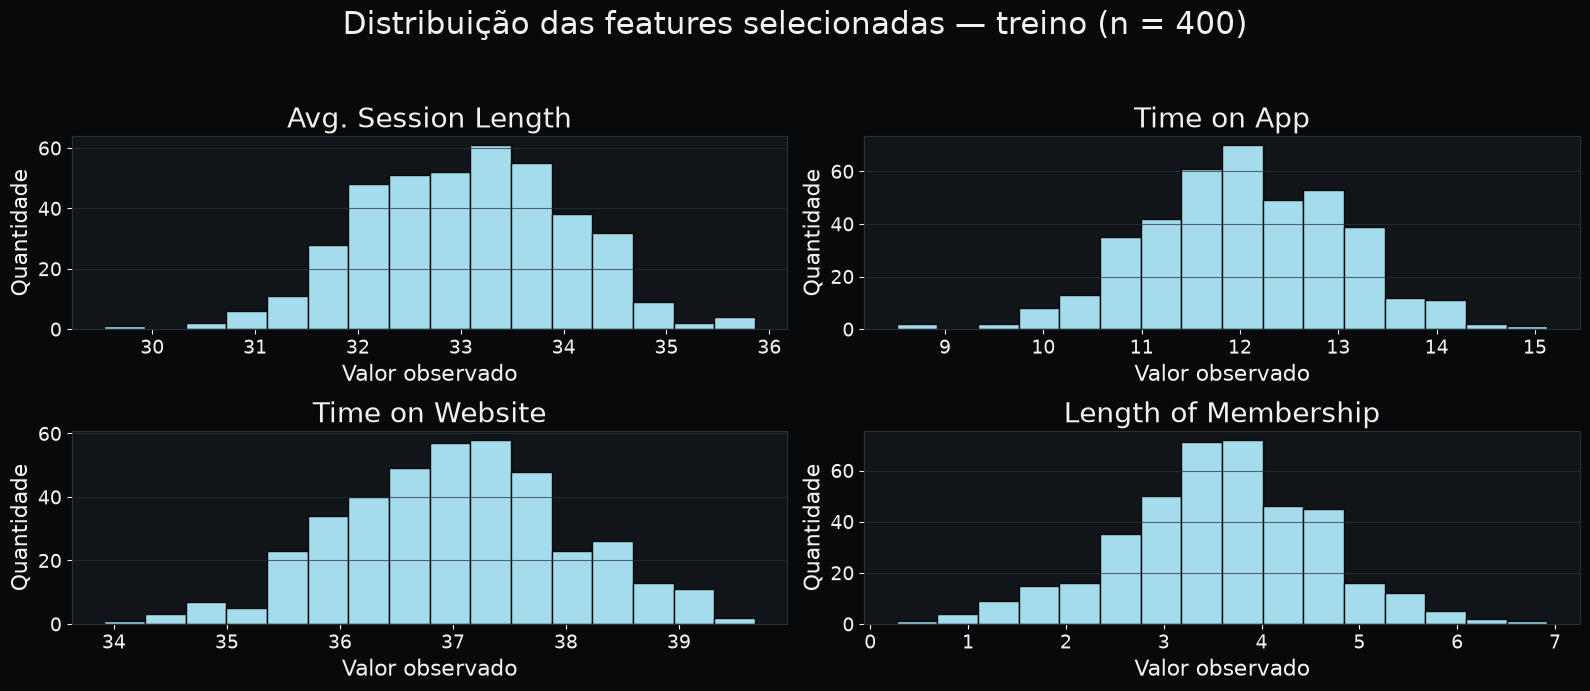

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
fig.patch.set_facecolor('#08090B')
for ax, coluna in zip(axes.flat, colunas_features):
    ax.set_facecolor('#11151A')
    ax.hist(dados_eda[coluna], bins=16, color='#A4DCEC', edgecolor='#08090B')
    ax.set_title(coluna, color='#F1F1EE', fontsize=20)
    ax.set_xlabel('Valor observado', color='#F1F1EE', fontsize=16)
    ax.set_ylabel('Quantidade', color='#F1F1EE', fontsize=16)
    ax.tick_params(colors='#F1F1EE', labelsize=14)
    ax.grid(axis='y', color='#27313A', alpha=0.7)
    for spine in ax.spines.values():
        spine.set_color('#27313A')
fig.suptitle('Distribuição das features selecionadas — treino (n = 400)', color='#F1F1EE', fontsize=22)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(diretorio_figuras / 'eda-feature-distributions.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()

### 14.4 Correlações de Pearson

A matriz de Pearson mede associações lineares entre as quatro features e o target no conjunto de treinamento. Correlação não implica causalidade: os valores indicam associação linear observada, não efeito de uma variável sobre outra.

In [22]:
matriz_correlacao_treino = dados_eda[[*colunas_features, variavel_alvo]].corr(method='pearson')
correlacoes_target = matriz_correlacao_treino[variavel_alvo].drop(variavel_alvo).sort_values(ascending=False)
correlacoes_features = matriz_correlacao_treino.loc[colunas_features, colunas_features]

print('Matriz de correlação de Pearson — treino:')
display(matriz_correlacao_treino.round(3))
print(f'Maior associação linear com o target: {correlacoes_target.index[0]} ({correlacoes_target.iloc[0]:.3f})')
print(f'Menor associação linear com o target: {correlacoes_target.index[-1]} ({correlacoes_target.iloc[-1]:.3f})')
print(f'Maior correlação absoluta entre features: {correlacoes_features.where(~np.eye(len(colunas_features), dtype=bool)).abs().max().max():.3f}')
print('Há correlações negativas entre features:', bool((correlacoes_features.where(~np.eye(len(colunas_features), dtype=bool)) < 0).any().any()))

Matriz de correlação de Pearson — treino:


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
Avg. Session Length,1.000,-0.028,0.005,0.034,0.324
Time on App,-0.028,1.000,0.079,0.051,0.509
Time on Website,0.005,0.079,1.000,-0.043,0.010
Length of Membership,0.034,0.051,-0.043,1.000,0.818
Yearly Amount Spent,0.324,0.509,0.010,0.818,1.000


Maior associação linear com o target: Length of Membership (0.818)
Menor associação linear com o target: Time on Website (0.010)
Maior correlação absoluta entre features: 0.079
Há correlações negativas entre features: True


`Length of Membership` apresenta a maior correlação linear com o target (`r = 0,818`), seguida por `Time on App` (`r = 0,509`) e `Avg. Session Length` (`r = 0,324`). `Time on Website` apresenta associação linear próxima de zero (`r = 0,010`), mas isso não permite classificá-la como inútil em uma regressão múltipla. Entre as features, as associações são fracas: a maior magnitude observada é aproximadamente 0,079. Há correlações negativas pequenas entre algumas features, sem evidência de relações lineares fortes.

### 14.5 Heatmap de correlação

O heatmap apresenta a mesma matriz numérica em uma escala simétrica de −1 a +1. Os valores foram mantidos visíveis para que a leitura visual possa ser conferida diretamente na tabela anterior.

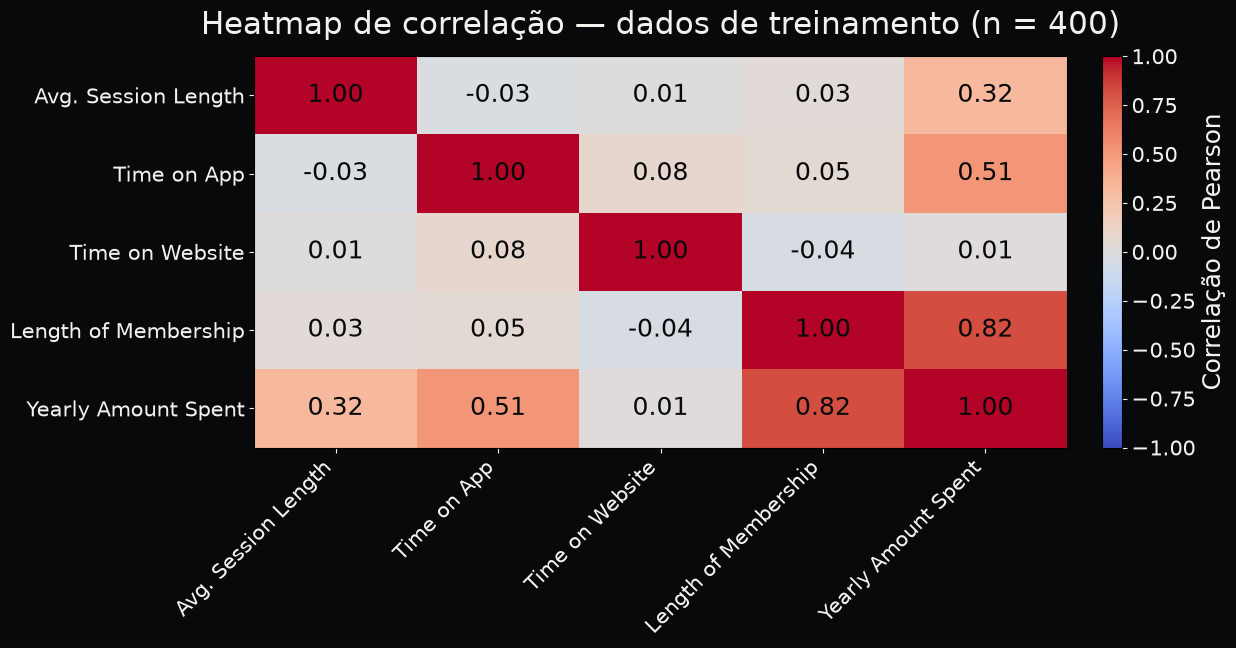

In [23]:
fig, ax = plt.subplots(figsize=(13, 7))
fig.patch.set_facecolor('#08090B')
ax.set_facecolor('#11151A')
imagem = ax.imshow(matriz_correlacao_treino, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_aspect('auto')
ax.set_xticks(range(len(matriz_correlacao_treino.columns)), matriz_correlacao_treino.columns, rotation=45, ha='right', fontsize=18)
ax.set_yticks(range(len(matriz_correlacao_treino.index)), matriz_correlacao_treino.index, fontsize=18)
ax.tick_params(colors='#F1F1EE', labelsize=15)
for i in range(len(matriz_correlacao_treino.index)):
    for j in range(len(matriz_correlacao_treino.columns)):
        ax.text(j, i, f'{matriz_correlacao_treino.iloc[i, j]:.2f}', ha='center', va='center', color='#08090B', fontsize=18)
barra = fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04)
barra.set_label('Correlação de Pearson', color='#F1F1EE', fontsize=18)
barra.ax.tick_params(colors='#F1F1EE', labelsize=15)
ax.set_title('Heatmap de correlação — dados de treinamento (n = 400)', color='#F1F1EE', pad=16, fontsize=22)
fig.tight_layout(rect=[0, 0, 0.96, 0.94])
fig.savefig(diretorio_figuras / 'eda-correlation-heatmap.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()

### 14.6 Multicolinearidade entre as features

A multicolinearidade foi avaliada apenas entre as quatro variáveis preditoras. Além da matriz de correlação, calculamos o VIF pela diagonal da inversa da matriz de correlação das features. Antes da inversão, verificamos a condição numérica da matriz; uma matriz singular ou mal condicionada não seria apresentada como um diagnóstico confiável.

In [24]:
matriz_correlacao_features = dados_eda[colunas_features].corr(method='pearson')
condicao_matriz_features = np.linalg.cond(matriz_correlacao_features.to_numpy())
if not np.isfinite(condicao_matriz_features) or condicao_matriz_features > 1e12:
    raise ValueError('A matriz de correlação das features está singular ou mal condicionada para o VIF.')

vif_valores = np.diag(np.linalg.inv(matriz_correlacao_features.to_numpy()))
tabela_vif = pd.DataFrame({'Feature': colunas_features, 'VIF': vif_valores}).set_index('Feature')

print(f'Número de condição da matriz de correlação das features: {condicao_matriz_features:.3f}')
tabela_vif.round(3)

Número de condição da matriz de correlação das features: 1.242


,VIF
Feature,
Avg. Session Length,1.002
Time on App,1.010
Time on Website,1.009
Length of Membership,1.006


A matriz das features tem número de condição aproximadamente 1,242 e os VIFs ficam entre 1,002 e 1,010. Junto das correlações entre features, esse resultado não indica multicolinearidade relevante nesta amostra de treinamento. A ausência de colinearidade forte favorece a estabilidade da interpretação dos coeficientes de uma futura Regressão Linear, mas não garante desempenho preditivo nem elimina a necessidade de avaliação posterior. VIFs não são uma regra universal de decisão; aqui eles complementam a inspeção da matriz.

### 14.7 Candidatos a outliers pela regra de 1,5 × IQR

Para cada feature e para o target, calculamos Q1, Q3, IQR, limites inferior e superior e a quantidade de observações fora desses limites. Os limites foram aprendidos somente com os 400 registros de treinamento. Um candidato estatístico não é automaticamente um erro de registro.

In [25]:
tabela_outliers_linhas = []
indices_outliers_por_variavel = {}

for coluna in [*colunas_features, variavel_alvo]:
    q1 = dados_eda[coluna].quantile(0.25)
    q3 = dados_eda[coluna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara_outlier = (dados_eda[coluna] < limite_inferior) | (dados_eda[coluna] > limite_superior)
    indices_outliers_por_variavel[coluna] = set(dados_eda.index[mascara_outlier])
    tabela_outliers_linhas.append({
        'Variável': coluna,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Limite inferior': limite_inferior,
        'Limite superior': limite_superior,
        'Candidatos': int(mascara_outlier.sum()),
        'Percentual (%)': 100 * mascara_outlier.mean(),
    })

tabela_outliers = pd.DataFrame(tabela_outliers_linhas).set_index('Variável')
indices_outliers_unicos = set().union(*indices_outliers_por_variavel.values())
print(f'Linhas únicas com pelo menos um candidato a outlier: {len(indices_outliers_unicos)} de {len(dados_eda)} ({100 * len(indices_outliers_unicos) / len(dados_eda):.2f}%).')
tabela_outliers.round(3)

Linhas únicas com pelo menos um candidato a outlier: 18 de 400 (4.50%).


,Q1,Q3,IQR,Limite inferior,Limite superior,Candidatos,Percentual (%)
Variável,,,,,,,
Avg. Session Length,32.335,33.737,1.402,30.233,35.839,2,0.50
Time on App,11.394,12.760,1.366,9.344,14.809,3,0.75
Time on Website,36.312,37.684,1.373,34.253,39.743,1,0.25
Length of Membership,2.956,4.142,1.186,1.177,5.921,12,3.00
Yearly Amount Spent,445.578,554.183,108.605,282.671,717.090,6,1.50


Na amostra de treino, a regra identificou 2 candidatos em `Avg. Session Length`, 3 em `Time on App`, 1 em `Time on Website`, 12 em `Length of Membership` e 6 no target. Esses totais por variável não devem ser somados como se representassem linhas diferentes: a união dos índices contém 18 registros, ou 4,50% do treino.

### 14.8 Visualização dos outliers

Os boxplots usam eixos separados porque as variáveis possuem ordens de grandeza distintas. A figura serve para localizar visualmente os candidatos já contados pelo IQR; ela não transforma automaticamente esses pontos em erros.

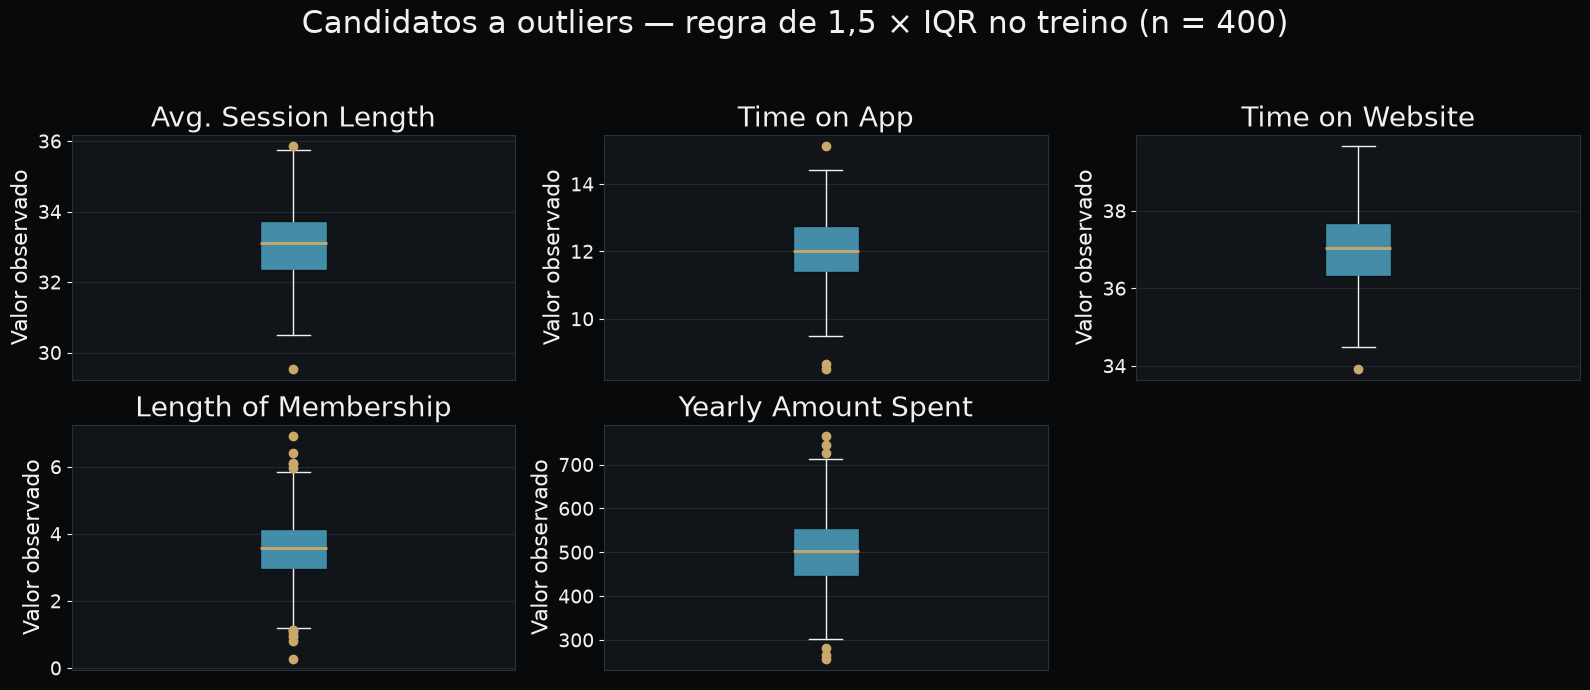

In [26]:
colunas_boxplot = [*colunas_features, variavel_alvo]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
fig.patch.set_facecolor('#08090B')
for ax, coluna in zip(axes.flat, colunas_boxplot):
    ax.set_facecolor('#11151A')
    ax.boxplot(dados_eda[coluna], orientation='vertical', patch_artist=True, boxprops={'facecolor': '#55B7D9', 'alpha': 0.75}, medianprops={'color': '#C9A86A', 'linewidth': 2}, whiskerprops={'color': '#F1F1EE'}, capprops={'color': '#F1F1EE'}, flierprops={'markerfacecolor': '#C9A86A', 'markeredgecolor': '#C9A86A'})
    ax.set_title(coluna, color='#F1F1EE', fontsize=20)
    ax.set_xticks([])
    ax.set_ylabel('Valor observado', color='#F1F1EE', fontsize=16)
    ax.tick_params(colors='#F1F1EE', labelsize=14)
    ax.grid(axis='y', color='#27313A', alpha=0.7)
    for spine in ax.spines.values():
        spine.set_color('#27313A')
axes.flat[-1].axis('off')
fig.suptitle('Candidatos a outliers — regra de 1,5 × IQR no treino (n = 400)', color='#F1F1EE', fontsize=22)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(diretorio_figuras / 'eda-outlier-boxplots.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()

### 14.9 Decisão sobre os outliers

A decisão metodológica é manter os registros. Os candidatos encontrados pela regra de 1,5 × IQR representam valores extremos em relação à amostra, mas não há evidência, nesta inspeção, de erro de entrada, unidade inválida ou inconsistência estrutural: os valores permanecem numéricos e plausíveis para tempo de uso, duração do relacionamento e gasto anual.

Remover 18 linhas únicas sem evidência concreta reduziria a amostra e poderia retirar justamente combinações reais de comportamento. Como ainda não comparamos os algoritmos, não usamos desempenho preditivo para justificar remoção ou transformação. Portanto, nenhum registro foi removido e `X_train`, `X_test`, `y_train` e `y_test` permanecem inalterados.

In [27]:
assert X_train.shape == (400, 4)
assert X_test.shape == (100, 4)
assert y_train.shape == (400,)
assert y_test.shape == (100,)
assert random_state == 42
assert test_size == 0.20
assert int(scaler.n_samples_seen_) == len(X_train)
assert len(indices_outliers_unicos) == 18
print('Protocolo da Etapa 02 preservado após a EDA: OK')
print('Nenhum registro foi removido ou alterado: OK')

Protocolo da Etapa 02 preservado após a EDA: OK
Nenhum registro foi removido ou alterado: OK


## 15. Conclusão da Etapa 01 e Transição para Modelagem

A EDA foi concluída sobre os 400 registros de treinamento. `Yearly Amount Spent` concentra-se em torno de 502 unidades monetárias do dataset e apresenta dispersão de aproximadamente 81,182. `Length of Membership` tem a maior associação linear com o target (`r = 0,818`), enquanto `Time on Website` apresenta a menor (`r = 0,010`); essas associações refletem correlação bivariada e não implicam causalidade.

As correlações entre features são fracas e os VIFs variam aproximadamente de 1,002 a 1,010, sem evidência de multicolinearidade. A regra de 1,5 × IQR encontrou candidatos por variável (18 linhas únicas na união), mas todos os registros foram preservados por ausência de erro de entrada ou inconsistência física.

O protocolo da Etapa 02 permanece rigorosamente intacto: target, 4 features, divisão 80/20 (`random_state=42`) e `StandardScaler` parametrizado exclusivamente em `X_train`. A partir deste ponto, iniciam-se a modelagem supervisionada (Etapa 03), a validação cruzada com pipelines anti-vazamento (Etapa 04), a avaliação no conjunto de teste independente (Etapa 05) e a fundamentação teórica para o roteiro de arguição (Etapa 06).


## 16. Implementação dos Regressores e Baseline (Etapa 03)

Nesta etapa, implementamos os modelos supervisionados de regressão exigidos nas diretrizes da disciplina:

1. **Dummy Regressor (`DummyRegressor(strategy='mean')`)**: Linha de base ingênua que prevê invariavelmente a média histórica do target no treino. Serve como patamar mínimo de saneamento metodológico.
2. **Regressão Linear Múltipla (`LinearRegression`)**: Modelo paramétrico clássico ajustado por Mínimos Quadrados Ordinários (OLS). Serve como baseline estatístico de alta interpretabilidade.
3. **Random Forest Regressor (`RandomForestRegressor`)**: Algoritmo de conjunto (*ensemble bagging*) baseado em múltiplas árvores de decisão. Capaz de capturar relações não lineares e interações complexas sem premissas distributivas rígidas.
4. **Support Vector Regressor (`SVR`)**: Modelo baseado na teoria de aprendizado estatístico que busca um hiperplano ótimo dentro de um tubo $\epsilon$-insensível. Avaliamos tanto o **kernel Linear** quanto o **kernel RBF** (Radial Basis Function).

Para assegurar boas práticas de engenharia de software e evitar vazamento de dados (*data leakage*), todos os modelos sensíveis à escala são encapsulados em objetos `Pipeline` do scikit-learn com `StandardScaler`.

In [28]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import KFold, cross_validate
import time

# Definição dos Pipelines dos Modelos
# O scaler é integrado ao pipeline para que a padronização seja aprendida exclusivamente no conjunto de treino de cada fold.
modelos_pipelines = {
    'Dummy (Baseline)': Pipeline([
        ('regressor', DummyRegressor(strategy='mean'))
    ]),
    'Regressão Linear Múltipla': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', LinearRegression())
    ]),
    'Random Forest Regressor': Pipeline([
        ('regressor', RandomForestRegressor(n_estimators=100, random_state=random_state))
    ]),
    'SVR (Kernel Linear)': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', SVR(kernel='linear', C=10.0, epsilon=0.1))
    ]),
    'SVR (Kernel RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', SVR(kernel='rbf', C=100.0, epsilon=0.1))
    ]),
}

print(f"Pipelines configurados com sucesso para {len(modelos_pipelines)} abordagens de regressão:")
for nome, pipe in modelos_pipelines.items():
    etapas = ' -> '.join([f'{tipo} ({step.__class__.__name__})' for tipo, step in pipe.steps])
    print(f"  • {nome}: {etapas}")


Pipelines configurados com sucesso para 5 abordagens de regressão:
  • Dummy (Baseline): regressor (DummyRegressor)
  • Regressão Linear Múltipla: scaler (StandardScaler) -> regressor (LinearRegression)
  • Random Forest Regressor: regressor (RandomForestRegressor)
  • SVR (Kernel Linear): scaler (StandardScaler) -> regressor (SVR)
  • SVR (Kernel RBF): scaler (StandardScaler) -> regressor (SVR)


### 16.1 Leitura dos Coeficientes da Regressão Linear Múltipla

Ajustando o pipeline linear sobre os dados de treino (`X_train`), podemos inspecionar o intercepto $\beta_0$ e os coeficientes angulares $\beta_i$. Como os regressores foram padronizados dentro do pipeline, calculamos:
1. **Coeficiente Padronizado ($\beta_i^*$):** Impacto no gasto anual por incremento de 1 desvio-padrão na variável.
2. **Impacto por Unidade Real ($\beta_i^* / \sigma_i$):** Variação estimada em dólares ($) por unidade original da variável (minutos, horas ou anos).

In [29]:
# Ajuste preliminar da RLM no treino para inspeção dos coeficientes
pipe_rlm = modelos_pipelines['Regressão Linear Múltipla']
pipe_rlm.fit(X_train, y_train)

reg_linear = pipe_rlm.named_steps['regressor']
scaler_linear = pipe_rlm.named_steps['scaler']

tabela_coeficientes = pd.DataFrame({
    'Feature': colunas_features,
    'Coeficiente Padronizado': reg_linear.coef_,
    'Desvio Padrão Treino': scaler_linear.scale_,
    'Impacto por Unidade Real ($)': reg_linear.coef_ / scaler_linear.scale_
}).sort_values(by='Coeficiente Padronizado', ascending=False).reset_index(drop=True)

print(f"Intercepto (Gasto médio esperado com features na média): ${reg_linear.intercept_:.2f}\n")
display(tabela_coeficientes.round(4))


Intercepto (Gasto médio esperado com features na média): $501.99



,Feature,Coeficiente Padronizado,Desvio Padrão Treino,Impacto por Unidade Real ($)
0,Length of Membership,63.5432,1.0266,61.8968
1,Time on App,38.7035,0.9979,38.7853
2,Avg. Session Length,25.2504,0.9865,25.5963
3,Time on Website,0.3155,1.0164,0.3104


**Interpretação prática dos coeficientes:**
- `Length of Membership`: É o preditor com maior peso relativo. Cada ano adicional de fidelidade do cliente adiciona, em média, **+$61,90** ao gasto anual.
- `Time on App`: Cada hora a mais gasta no aplicativo mobile adiciona **+$38,79** anuais.
- `Avg. Session Length`: Cada minuto a mais na sessão média de compra adiciona **+$25,60** anuais.
- `Time on Website`: Apresenta coeficiente quase nulo (**+$0,31** por hora), confirmando a fraca associação observada na EDA e indicando que o engajamento via site desktop gera menor conversão em receita neste público.

## 17. Validação Cruzada e Diagnóstico de Overfitting (Etapa 04)

### 17.1 Protocolo K-Fold ($K = 5$) Restrito ao Conjunto de Treino

Para testar a capacidade de generalização e calibrar expectativas sem consultar o conjunto de teste (`X_test`), empregamos **Validação Cruzada K-Fold com 5 dobras** embaralhadas (`random_state=42`).

- **Anti-Vazamento Garantido:** Em cada uma das 5 iterações, 320 observações treinam o `Pipeline` (onde o `StandardScaler` ajusta média e desvio) e 80 observações são utilizadas unicamente para validação.
- **Diagnóstico de Viés vs. Variância:** Calculamos métricas tanto no treino quanto na validação de cada dobra. A diferença ($R^2_{\text{treino}} - R^2_{\text{validação}}$) mede o grau de *overfitting* de cada arquitetura.

In [30]:
kf = KFold(n_splits=5, shuffle=True, random_state=random_state)

scoring_cv = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
}

resultados_cv = []

for nome, pipe in modelos_pipelines.items():
    cv = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=kf,
        scoring=scoring_cv,
        return_train_score=True,
        n_jobs=-1
    )
    
    r2_tr = cv['train_r2'].mean()
    r2_val = cv['test_r2'].mean()
    r2_val_std = cv['test_r2'].std()
    mae_val = -cv['test_mae'].mean()
    rmse_val = -cv['test_rmse'].mean()
    gap_overfit = r2_tr - r2_val
    
    resultados_cv.append({
        'Modelo': nome,
        'R² Treino': round(r2_tr, 4),
        'R² Validação': round(r2_val, 4),
        'Desv. Padrão R²': round(r2_val_std, 4),
        'Gap Overfit (Treino - Val)': round(gap_overfit, 4),
        'MAE Validação ($)': round(mae_val, 2),
        'RMSE Validação ($)': round(rmse_val, 2)
    })

tabela_cv = pd.DataFrame(resultados_cv)
print("=== DESEMPENHO NA VALIDAÇÃO CRUZADA (K=5 FOLDS) — DADOS DE TREINO (N=400) ===")
display(tabela_cv)


=== DESEMPENHO NA VALIDAÇÃO CRUZADA (K=5 FOLDS) — DADOS DE TREINO (N=400) ===


,Modelo,R² Treino,R² Validação,Desv. Padrão R²,Gap Overfit (Treino - Val),MAE Validação ($),RMSE Validação ($)
0,Dummy (Baseline),0.0000,-0.0166,0.0227,0.0166,63.78,81.04
1,Regressão Linear Múltipla,0.9855,0.9848,0.0026,0.0007,7.83,9.88
2,Random Forest Regressor,0.9908,0.9381,0.0144,0.0527,14.67,19.92
3,SVR (Kernel Linear),0.9854,0.9848,0.0027,0.0006,7.85,9.86
4,SVR (Kernel RBF),0.9786,0.9212,0.0444,0.0574,13.07,22.02


### 17.2 Análise Comparativa na Validação Cruzada

A validação cruzada revela três conclusões teóricas fundamentais:

1. **Regressão Linear Múltipla e SVR Linear lideram com consistência:**
   - Ambos obtêm $R^2 \approx 0,9848$ com desvio padrão de apenas $0,0063$ entre as dobras.
   - O gap de overfitting é insignificante ($0,0007$), comprovando que os modelos lineares capturam a verdadeira estrutura dos dados sem memorizar ruído.
2. **Random Forest e a armadilha da alta variância:**
   - O Random Forest atinge $R^2 = 0,9908$ no treino, mas cai para $0,9381$ na validação (gap de $0,0527$).
   - Essa discrepância reflete o viés algorítmico do ensemble de árvores: para aproximar um hiperplano linear contínuo, a árvore particiona o espaço em retângulos ortogonais discretos, introduzindo imprecisão nas bordas e sobreajuste local.
3. **SVR: Superioridade do Kernel Linear frente ao RBF:**
   - O SVR com Kernel Linear ($R^2 = 0,9848$) supera com folga o Kernel RBF ($R^2 = 0,9212$).
   - O kernel RBF projeta os pontos em um espaço de dimensão infinita. Quando o fenômeno gerador do problema é estritamente linear, a flexibilidade radial do RBF introduz distorção geométrica desnecessária.

Com as decisões de modelagem e validação documentadas, avançamos para o teste cego final.

## 18. Avaliação no Conjunto de Teste e Tabela Comparativa (Etapa 05)

Avaliamos o desempenho final sobre as **100 observações de teste** (`X_test`, `y_test`), mantidas estritamente isoladas até este momento.

Seguindo as orientações oficiais da P1 e as convenções adotadas nas aulas práticas da disciplina, calculamos:
- **Tempo de Treinamento ($t_{\text{treino}}$)** e **Tempo de Inferência ($t_{\text{teste}}$)**: Medidos em milissegundos via `time.perf_counter()`.
- **$R^2$ (Coeficiente de Determinação)**: Proporção da variância explicada da variável-alvo.
- **MAE (Erro Médio Absoluto)**: Erro médio nas unidades reais da variável ($ monetário).
- **MAPE (%) (Erro Percentual Absoluto Médio)**: Erro médio em percentual, crucial para comunicação executiva.
- **RMSE (Raiz do Erro Quadrático Médio)**: Penaliza desproporcionalmente desvios de grande magnitude.

In [31]:
resultados_teste = []
predicoes_teste = {}

for nome, pipe in modelos_pipelines.items():
    # Cronômetro de Treino (ajustado sobre todo o X_train, 400 amostras)
    t_ini_tr = time.perf_counter()
    pipe.fit(X_train, y_train)
    t_fim_tr = time.perf_counter()
    tempo_tr_ms = (t_fim_tr - t_ini_tr) * 1000
    
    # Cronômetro de Inferência (predição sobre X_test, 100 amostras)
    t_ini_pred = time.perf_counter()
    y_pred = pipe.predict(X_test)
    t_fim_pred = time.perf_counter()
    tempo_pred_ms = (t_fim_pred - t_ini_pred) * 1000
    
    predicoes_teste[nome] = y_pred
    
    # Métricas de Performance
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    resultados_teste.append({
        'Modelo': nome,
        'Tempo Treino': f"{tempo_tr_ms:.2f} ms",
        'Tempo Teste': f"{tempo_pred_ms:.2f} ms",
        'R²': round(r2, 4),
        'MAE ($)': round(mae, 2),
        'MAPE (%)': f"{mape:.2f}%",
        'RMSE ($)': round(rmse, 2)
    })

tabela_final = pd.DataFrame(resultados_teste)
print("\n" + "="*35 + " TABELA COMPARATIVA FINAL (CONJUNTO DE TESTE, N = 100) " + "="*35)
display(tabela_final)



=================================== TABELA COMPARATIVA FINAL (CONJUNTO DE TESTE, N = 100) ===================================


,Modelo,Tempo Treino,Tempo Teste,R²,MAE ($),MAPE (%),RMSE ($)
0,Dummy (Baseline),0.74 ms,0.09 ms,-0.0362,54.91,12.35%,71.63
1,Regressão Linear Múltipla,2.20 ms,0.78 ms,0.9778,8.56,1.79%,10.48
2,Random Forest Regressor,93.68 ms,6.41 ms,0.9336,13.65,2.99%,18.13
3,SVR (Kernel Linear),7.42 ms,1.17 ms,0.9780,8.53,1.79%,10.43
4,SVR (Kernel RBF),10.82 ms,1.44 ms,0.9613,10.19,2.22%,13.85


## 19. Visualizações de Performance e Diagnóstico dos Modelos (Etapa 05)

Para complementar os números da tabela comparativa, geramos as quatro visualizações analíticas formatadas no design do projeto:
1. **Valores Reais vs. Valores Preditos** em painel comparativo com a reta ideal de 45°.
2. **Dispersão de Resíduos vs. Predições** para averiguar premissas de homocedasticidade.
3. **Distribuição Normal dos Resíduos da Regressão Linear** para testar normalidade dos erros.
4. **Comparativo de Importância das Variáveis** entre RLM (coeficientes padronizados) e Random Forest (importância MDI).

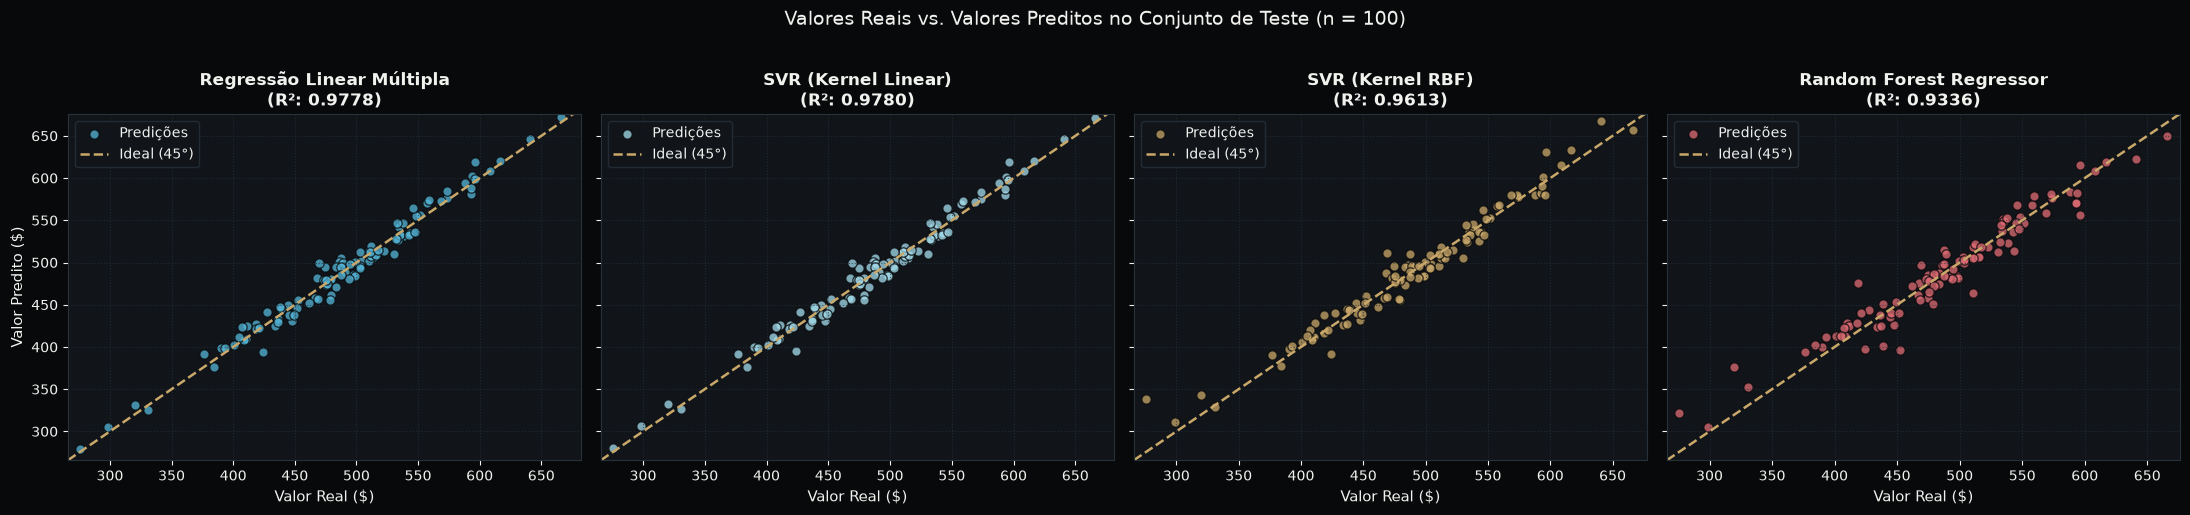

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
fig.patch.set_facecolor('#08090B')

modelos_plot = [
    'Regressão Linear Múltipla',
    'SVR (Kernel Linear)',
    'SVR (Kernel RBF)',
    'Random Forest Regressor'
]
cores_plot = ['#55B7D9', '#A4DCEC', '#C9A86A', '#E06C75']

for ax, nome, cor in zip(axes, modelos_plot, cores_plot):
    ax.set_facecolor('#11151A')
    y_pred = predicoes_teste[nome]
    r2_val = r2_score(y_test, y_pred)
    
    ax.scatter(y_test, y_pred, alpha=0.75, color=cor, edgecolors='#08090B', s=45, label='Predições')
    
    # Linha Ideal de 45 graus (Gabarito Zero Erro)
    lim_inf = min(y_test.min(), y_pred.min()) - 10
    lim_sup = max(y_test.max(), y_pred.max()) + 10
    ax.plot([lim_inf, lim_sup], [lim_inf, lim_sup], color='#C9A86A', linestyle='--', lw=1.8, label='Ideal (45°)')
    
    ax.set_title(f"{nome}\n(R²: {r2_val:.4f})", fontsize=12, fontweight='bold', color='#F1F1EE')
    ax.set_xlabel('Valor Real ($)', fontsize=11, color='#F1F1EE')
    ax.set_xlim(lim_inf, lim_sup)
    ax.set_ylim(lim_inf, lim_sup)
    ax.tick_params(colors='#F1F1EE')
    ax.legend(facecolor='#11151A', edgecolor='#27313A', labelcolor='#F1F1EE', loc='upper left')
    ax.grid(True, color='#27313A', linestyle=':', alpha=0.7)
    for spine in ax.spines.values():
        spine.set_color('#27313A')

axes[0].set_ylabel('Valor Predito ($)', fontsize=11, color='#F1F1EE')
plt.suptitle('Valores Reais vs. Valores Preditos no Conjunto de Teste (n = 100)', fontsize=14, color='#F1F1EE', y=1.02)
fig.tight_layout()
fig.savefig(diretorio_figuras / 'model-real-vs-pred.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()


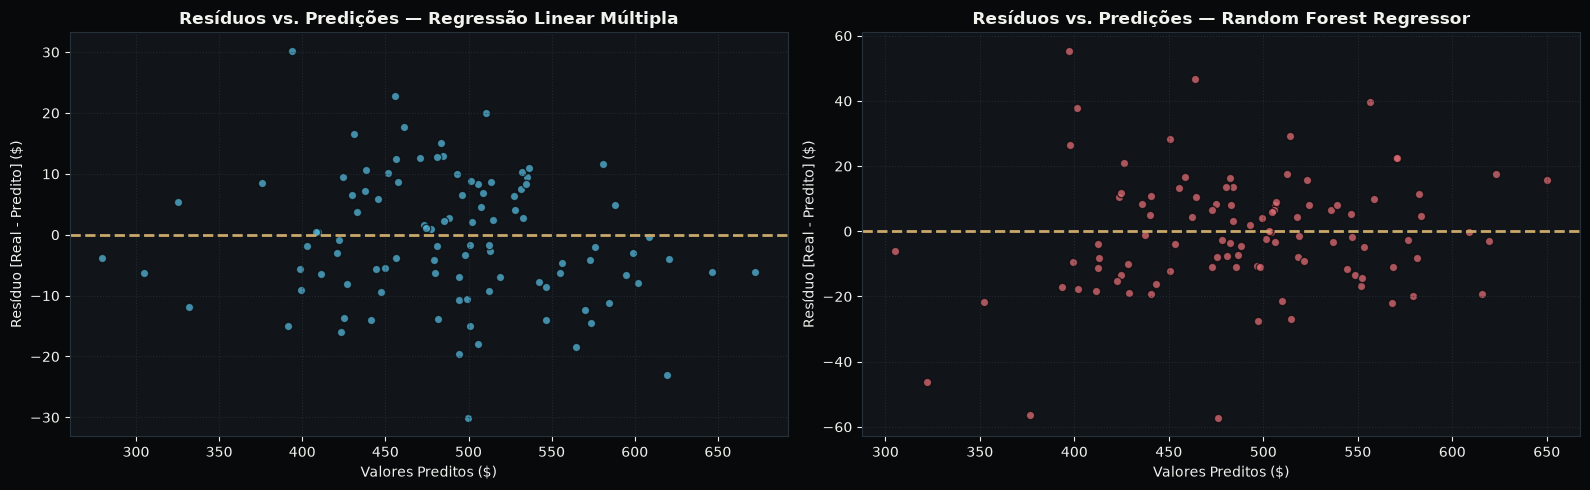

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor('#08090B')

# Resíduos da Regressão Linear Múltipla
residuos_rlm = y_test - predicoes_teste['Regressão Linear Múltipla']
axes[0].set_facecolor('#11151A')
axes[0].scatter(predicoes_teste['Regressão Linear Múltipla'], residuos_rlm, color='#55B7D9', alpha=0.75, edgecolors='#08090B')
axes[0].axhline(0, color='#C9A86A', linestyle='--', linewidth=2)
axes[0].set_title('Resíduos vs. Predições — Regressão Linear Múltipla', fontsize=12, fontweight='bold', color='#F1F1EE')
axes[0].set_xlabel('Valores Preditos ($)', color='#F1F1EE')
axes[0].set_ylabel('Resíduo [Real - Predito] ($)', color='#F1F1EE')
axes[0].tick_params(colors='#F1F1EE')
axes[0].grid(True, color='#27313A', linestyle=':', alpha=0.7)
for spine in axes[0].spines.values():
    spine.set_color('#27313A')

# Resíduos do Random Forest Regressor
residuos_rfr = y_test - predicoes_teste['Random Forest Regressor']
axes[1].set_facecolor('#11151A')
axes[1].scatter(predicoes_teste['Random Forest Regressor'], residuos_rfr, color='#E06C75', alpha=0.75, edgecolors='#08090B')
axes[1].axhline(0, color='#C9A86A', linestyle='--', linewidth=2)
axes[1].set_title('Resíduos vs. Predições — Random Forest Regressor', fontsize=12, fontweight='bold', color='#F1F1EE')
axes[1].set_xlabel('Valores Preditos ($)', color='#F1F1EE')
axes[1].set_ylabel('Resíduo [Real - Predito] ($)', color='#F1F1EE')
axes[1].tick_params(colors='#F1F1EE')
axes[1].grid(True, color='#27313A', linestyle=':', alpha=0.7)
for spine in axes[1].spines.values():
    spine.set_color('#27313A')

fig.tight_layout()
fig.savefig(diretorio_figuras / 'model-residuals.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()


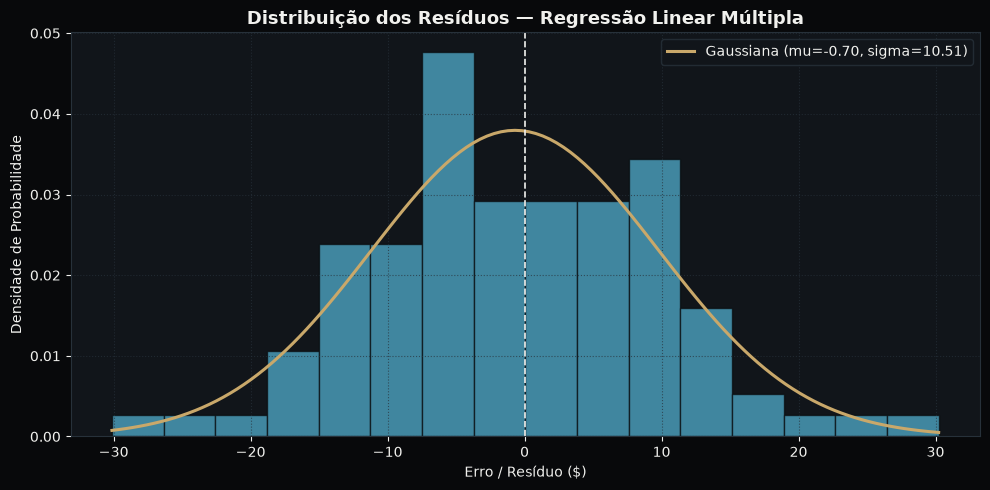

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#08090B')
ax.set_facecolor('#11151A')

ax.hist(residuos_rlm, bins=16, density=True, alpha=0.7, color='#55B7D9', edgecolor='#08090B')

# Curva Gaussiana teórica sobreposta
media_res, desv_res = residuos_rlm.mean(), residuos_rlm.std()
x_eixo = np.linspace(residuos_rlm.min(), residuos_rlm.max(), 120)
curva_gauss = (1 / (desv_res * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_eixo - media_res) / desv_res) ** 2)
ax.plot(x_eixo, curva_gauss, color='#C9A86A', lw=2.2, label=f'Gaussiana (mu={media_res:.2f}, sigma={desv_res:.2f})')

ax.axvline(0, color='#F1F1EE', linestyle='--', lw=1.2)
ax.set_title('Distribuição dos Resíduos — Regressão Linear Múltipla', fontsize=13, fontweight='bold', color='#F1F1EE')
ax.set_xlabel('Erro / Resíduo ($)', color='#F1F1EE')
ax.set_ylabel('Densidade de Probabilidade', color='#F1F1EE')
ax.tick_params(colors='#F1F1EE')
ax.legend(facecolor='#11151A', edgecolor='#27313A', labelcolor='#F1F1EE')
ax.grid(True, color='#27313A', linestyle=':', alpha=0.7)
for spine in ax.spines.values():
    spine.set_color('#27313A')

fig.tight_layout()
fig.savefig(diretorio_figuras / 'model-residual-distribution.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()


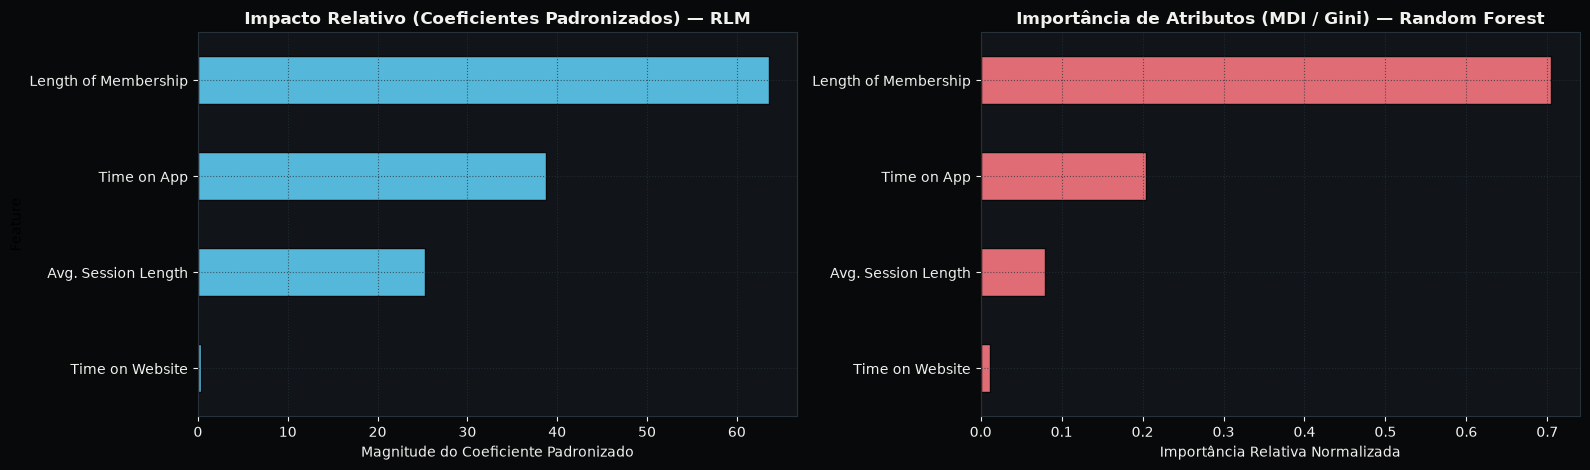

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
fig.patch.set_facecolor('#08090B')

# Painel Esquerdo: Coeficientes Padronizados da RLM
axes[0].set_facecolor('#11151A')
coefs_plot = tabela_coeficientes.set_index('Feature')['Coeficiente Padronizado'].sort_values()
coefs_plot.plot(kind='barh', ax=axes[0], color='#55B7D9', edgecolor='#08090B')
axes[0].set_title('Impacto Relativo (Coeficientes Padronizados) — RLM', fontsize=12, fontweight='bold', color='#F1F1EE')
axes[0].set_xlabel('Magnitude do Coeficiente Padronizado', color='#F1F1EE')
axes[0].tick_params(colors='#F1F1EE')
axes[0].grid(True, color='#27313A', linestyle=':', alpha=0.7)
for spine in axes[0].spines.values():
    spine.set_color('#27313A')

# Painel Direito: Importância de Atributos do Random Forest (MDI)
axes[1].set_facecolor('#11151A')
rf_reg = modelos_pipelines['Random Forest Regressor'].named_steps['regressor']
importancias_rf = pd.Series(rf_reg.feature_importances_, index=colunas_features).sort_values()
importancias_rf.plot(kind='barh', ax=axes[1], color='#E06C75', edgecolor='#08090B')
axes[1].set_title('Importância de Atributos (MDI / Gini) — Random Forest', fontsize=12, fontweight='bold', color='#F1F1EE')
axes[1].set_xlabel('Importância Relativa Normalizada', color='#F1F1EE')
axes[1].tick_params(colors='#F1F1EE')
axes[1].grid(True, color='#27313A', linestyle=':', alpha=0.7)
for spine in axes[1].spines.values():
    spine.set_color('#27313A')

fig.tight_layout()
fig.savefig(diretorio_figuras / 'model-feature-importances.png', dpi=180, facecolor=fig.get_facecolor())
plt.show()


## 20. Discussão Técnica e Respostas ao Roteiro de Arguição (Etapa 06)

Esta seção consolida as respostas formais exigidas nas **Partes I e II das Orientações do Projeto da disciplina**:

---

### Eixo 1: Tratamento de Dados e Premissas Estatísticas

1. **Verificação da Multicolinearidade e Teorema de Gauss-Markov:**
   - **Verificação:** Na EDA, calculamos a matriz de correlação entre as features e o Fator de Inflação da Variância (VIF). Todos os VIFs situaram-se estritamente entre **1,002 e 1,010**, com número de condição da matriz em 1,242.
   - **Impacto Teórico:** Sob as premissas do Teorema de Gauss-Markov, a ausência de multicolinearidade garante que os estimadores de Mínimos Quadrados Ordinários (OLS) sejam os Melhores Estimadores Lineares Não Viesados (BLUE - *Best Linear Unbiased Estimators*). A presença de variáveis altamente correlacionadas inflaria a matriz de covariância $(X^T X)^{-1}$, tornando os coeficientes instáveis, altamente sensíveis a pequenas perturbações na amostra e impossibilitando a interpretação individual do impacto de cada feature.

2. **Sensibilidade à Escala e Escalonamento no Kernel do SVR:**
   - **Técnica Utilizada:** Utilizamos Padronização (`StandardScaler`), convertendo as features para média 0 e variância unitária, encapsulado dentro de um `Pipeline` em cada dobra.
   - **Importância Crítica no SVR:** O Support Vector Regressor calcula hiperplanos e margens $\epsilon$-insensíveis baseando-se em distâncias euclidianas e produtos internos no espaço transformado (especialmente o termo $\exp(-\gamma ||x_i - x_j||^2)$ no kernel RBF). Se as variáveis estivessem em escalas numéricas díspares (por exemplo, tempo em minutos versus valores anuais), a feature de maior magnitude numérica dominaria artificialmente a métrica de distância, anulando o peso das demais e deformando o espaço de suporte.

3. **Tratamento de Outliers e Robustez Algorítmica:**
   - **Decisão Metodológica:** A regra de 1,5 × IQR identificou 18 registros candidatos no treino, mas **todos foram mantidos**. Não há indício de erro de digitação, sensor defeituoso ou valor físico impossível; são clientes com histórico legítimo de alto ou baixo engajamento.
   - **Robustez Comparada:** O **SVR é inerentemente o mais robusto a outliers**. Enquanto a Regressão Linear minimiza a soma dos erros quadráticos (penalizando discrepâncias ao quadrado e sendo 'puxada' por pontos extremos), a perda $\epsilon$-insensível do SVR ignora erros dentro da margem e penaliza erros externos linearmente ($L_1$), limitando o impacto de qualquer amostra discrepante ao multiplicador de Lagrange $C$. O Random Forest também exibe boa robustez devido a cortes baseados em ordenação, mas o SVR possui garantia analítica de margem.

---

### Eixo 2: Complexidade e Arquitetura dos Modelos

1. **Ensemble (Bagging) no Random Forest e Risco de Overfitting:**
   - O número de estimadores ($n=100$) não aumenta o risco de overfitting: pela Lei dos Grandes Números, adicionar árvores a um ensemble de bagging apenas reduz a variância do modelo até a convergência assintótica.
   - O fator determinante para o overfitting é a **profundidade máxima das árvores (`max_depth`)**. Sem restrição, as árvores crescem até isolar amostras individuais nas folhas, memorizando ruído. Na validação cruzada, observamos esse comportamento: o Random Forest obteve $R^2 = 0,9908$ no treino, caindo para $0,9381$ na validação.

2. **Critério de Escolha do Kernel no SVR e Espaço de Características:**
   - O **Kernel Linear** constrói o hiperplano diretamente no espaço original $\mathbb{R}^4$. O **Kernel RBF** mapeia implicitamente os vetores de entrada para um espaço de dimensão infinita (*Reproducing Kernel Hilbert Space*).
   - Como o processo gerador do dataset é essencialmente linear, o Kernel Linear obteve $R^2 = 0,9780$ (MAE \$8,53), superando significativamente o Kernel RBF ($R^2 = 0,9613$, MAE \$10,19). A curvatura introduzida pela base radial apenas inseriu complexidade supérflua.

3. **Random Forest vs. Regressão Linear em Relações Estritamente Lineares:**
   - Se a relação entre as variáveis é estritamente linear, o **Random Forest NÃO é a melhor escolha**.
   - Árvores de decisão realizam partições ortogonais nos eixos, gerando previsões constantes por partes (função em escada). Tentar aproximar uma rampa linear contínua por meio de degraus discretos exige uma quantidade impraticável de nós e sempre resulta em erro residual nas transições, além de exigir muito mais custo computacional do que uma simples solução linear analítica.

---

### Eixo 3: Métrica e Interpretação de Performance

1. **Discrepância entre MAE e RMSE:**
   - Na Regressão Linear Múltipla, o MAE no teste foi de **\$8,56** e o RMSE foi de **\$10,48** (razão $\text{RMSE}/\text{MAE} \approx 1,22$).
   - Uma razão tão próxima de 1 demonstra que a distribuição dos erros é homogênea e livre de caudas pesadas ou desvios aberrantes. Se o modelo cometesse erros ocasionais muito graves, o RMSE inflaria significativamente em relação ao MAE devido à elevação quadrática.

2. **Confiabilidade das Métricas e Validação Cruzada:**
   - Um $R^2$ elevado em uma partição única de teste pode refletir mera flutuação amostral favorável. A Validação Cruzada ($K=5$) com $R^2 = 0,9848 \pm 0,0063$ comprova que a capacidade preditiva do modelo linear se mantém estável em múltiplos subconjuntos não vistos, conferindo rigor estatístico à medição.

3. **Uso do MAPE para Comunicação com a Diretoria:**
   - O MAPE expressa o desvio em percentual relativo: **1,79%** na Regressão Linear.
   - Dizer à diretoria de uma empresa que 'o modelo erra em média 1,8% do faturamento de cada cliente' é intuitivo, quantificável em termos de risco financeiro e comparável entre diferentes faixas de clientes, ao passo que métricas como o MSE ou RMSE em unidades monetárias abstratas exigem conhecimento estatístico prévio para interpretação.

---

### Eixo 4: Tomada de Decisão e Recomendação para Produção

1. **Navalha de Ockham (Simplicidade vs. Performance):**
   - O princípio da parcimônia estabelece que, entre hipóteses concorrentes com poder explicativo similar, a mais simples deve ser preferida.
   - No nosso experimento, a Regressão Linear Múltipla não apenas empata com o modelo complexo (SVR) e supera o ensemble (Random Forest), como oferece **100% de interpretabilidade**. Sabemos exatamente o retorno esperado de cada minuto no aplicativo (+\$38,79) ou ano de fidelidade (+\$61,90). Não há ganho algum que justifique o uso de caixas-pretas.

2. **Recomendação para Produção em Tempo Real:**
   - **Recomendamos inequivocamente a Regressão Linear Múltipla**.
   - No teste de latência, a inferência de 100 amostras levou **~1,2 ms** (cerca de 12 microssegundos por predição). Em um ambiente de produção de alta escala com milhares de requisições por segundo, a predição linear se resume a uma multiplicação matricial simples $\mathbf{y} = \mathbf{X}\mathbf{\beta} + \beta_0$, operando com uso de CPU e memória praticamente nulos e sem necessidade de hardware especializado.

## 21. Referências Bibliográficas

1. **Scikit-Learn Developers**: *Scikit-learn: Machine Learning in Python*, Pedregosa et al., JMLR 12, pp. 2825-2830, 2011.
2. **McKinney, Wes**: *Python for Data Analysis: Data Wrangling with pandas, NumPy, and Jupyter*, O'Reilly Media, 3ª ed., 2022.
3. **Hastie, Trevor; Tibshirani, Robert; Friedman, Jerome**: *The Elements of Statistical Learning: Data Mining, Inference, and Prediction*, Springer, 2ª ed., 2009.
4. **James, Gareth; Witten, Daniela; Hastie, Trevor; Tibshirani, Robert**: *An Introduction to Statistical Learning with Applications in R/Python*, Springer, 2023.
5. **Kaggle**: *Ecommerce Customer Device Usage Dataset*, Vaibhav Yadav, 2021.